# Carbon Emission Forecasting:
### Predict Industrial Carbon Emissions ($tCO_2e$) using Python and LSTM Deep Learning

---
## Section 1: Data Understanding

### Step 1.1: Import Essential Libraries


In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import json
import joblib

import warnings
warnings.filterwarnings('ignore')

### Step 1.2: Import Machine Learning and Deep Learning Tools

In [2]:
from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

### Step 1.3: Load the Dataset from CSV
We use `pd.read_csv()` to load our carbon emission dataset into a pandas DataFrame called `df`.


In [3]:
df = pd.read_csv("carbon_emission_dataset_with_Industry.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [4]:
df.head()

,Company_ID,Date,Sector,Total_Energy_Consumption_kWh,Renewable_Energy_Consumption_kWh,NonRenewable_Energy_Consumption_kWh,Production_Output_Units,Supply_Chain_Transport_km,Supply_Chain_Transport_Mode,Raw_Material_Usage_kg,...,Carbon_Tax_USD,Process_Efficiency_Percent,Employment_Count,Public_Acceptance_Index,Carbon_Reduction_Strategy,Strategy_Implementation_Cost_USD,Expected_Carbon_Reduction_Percent,Expected_Renewable_Share_Percent,Social_Impact_Score,Industry_Sectors
0,C001,2024-01-01,Manufacturing,53751.61,12766.80,40984.81,3008.90,3814.12,Truck,51334.48,...,338.76,81.07,2128,0.77,Process Reengineering,188176.25,16.79,40.89,0.40,Steel Manufacturing
1,C001,2024-01-02,Manufacturing,170872.89,76733.84,94139.05,4062.25,1199.66,Air,17154.72,...,1073.13,69.26,855,0.77,Efficiency Upgrade,489246.31,12.57,58.19,0.86,Cement Production
2,C001,2024-01-03,Manufacturing,142777.96,75794.17,66983.79,6196.17,3670.57,Truck,56288.43,...,1390.41,90.33,3613,0.48,Carbon Tax Compliance,165061.64,12.11,68.14,0.79,Automotive Industry
3,C001,2024-01-04,Manufacturing,152532.15,20698.80,131833.35,6714.80,2903.63,Ship,21438.17,...,1942.56,79.49,3156,0.85,Efficiency Upgrade,191619.23,5.64,23.30,0.55,Logistics
4,C001,2024-01-05,Manufacturing,81647.43,46657.82,34989.61,8887.31,1916.05,Rail,37694.23,...,472.20,68.63,4915,0.47,Process Reengineering,459129.15,12.99,65.44,0.95,Steel Manufacturing


In [5]:
df.tail()

,Company_ID,Date,Sector,Total_Energy_Consumption_kWh,Renewable_Energy_Consumption_kWh,NonRenewable_Energy_Consumption_kWh,Production_Output_Units,Supply_Chain_Transport_km,Supply_Chain_Transport_Mode,Raw_Material_Usage_kg,...,Carbon_Tax_USD,Process_Efficiency_Percent,Employment_Count,Public_Acceptance_Index,Carbon_Reduction_Strategy,Strategy_Implementation_Cost_USD,Expected_Carbon_Reduction_Percent,Expected_Renewable_Share_Percent,Social_Impact_Score,Industry_Sectors
18245,C050,2024-12-26,Transport,69673.43,29071.24,40602.19,9013.46,2744.47,Truck,40063.55,...,701.61,75.53,4335,0.76,Carbon Tax Compliance,484138.46,5.48,47.70,0.83,Cement Production
18246,C050,2024-12-27,Transport,147667.28,24376.01,123291.27,6059.68,2135.77,Air,53646.80,...,1137.60,79.08,1067,0.82,Efficiency Upgrade,314618.29,7.35,28.79,0.45,Automotive Industry
18247,C050,2024-12-28,Transport,59522.00,34483.55,25038.45,2638.28,1924.02,Ship,45947.56,...,282.59,60.57,2719,0.32,Process Reengineering,189371.60,17.59,70.24,0.81,Logistics
18248,C050,2024-12-29,Transport,97234.51,12443.10,84791.41,5853.44,1279.10,Rail,30134.05,...,1001.77,67.56,4275,0.50,Carbon Tax Compliance,224436.86,6.67,23.52,0.65,Steel Manufacturing
18249,C050,2024-12-30,Transport,163312.60,84313.71,78998.89,2066.23,1446.52,Ship,72052.38,...,676.58,82.55,3302,0.79,Process Reengineering,269532.13,15.36,60.63,0.83,Cement Production


In [6]:
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows   : 18250
Number of columns: 22


In [7]:
list(df.columns)

['Company_ID',
 'Date',
 'Sector',
 'Total_Energy_Consumption_kWh',
 'Renewable_Energy_Consumption_kWh',
 'NonRenewable_Energy_Consumption_kWh',
 'Production_Output_Units',
 'Supply_Chain_Transport_km',
 'Supply_Chain_Transport_Mode',
 'Raw_Material_Usage_kg',
 'Carbon_Emission_tCO2e_TARGET',
 'Energy_Cost_USD',
 'Carbon_Tax_USD',
 'Process_Efficiency_Percent',
 'Employment_Count',
 'Public_Acceptance_Index',
 'Carbon_Reduction_Strategy',
 'Strategy_Implementation_Cost_USD',
 'Expected_Carbon_Reduction_Percent',
 'Expected_Renewable_Share_Percent',
 'Social_Impact_Score',
 'Industry_Sectors']

In [8]:
df.dtypes

Company_ID                              object
Date                                    object
Sector                                  object
Total_Energy_Consumption_kWh           float64
Renewable_Energy_Consumption_kWh       float64
NonRenewable_Energy_Consumption_kWh    float64
Production_Output_Units                float64
Supply_Chain_Transport_km              float64
Supply_Chain_Transport_Mode             object
Raw_Material_Usage_kg                  float64
Carbon_Emission_tCO2e_TARGET           float64
Energy_Cost_USD                        float64
Carbon_Tax_USD                         float64
Process_Efficiency_Percent             float64
Employment_Count                         int64
Public_Acceptance_Index                float64
Carbon_Reduction_Strategy               object
Strategy_Implementation_Cost_USD       float64
Expected_Carbon_Reduction_Percent      float64
Expected_Renewable_Share_Percent       float64
Social_Impact_Score                    float64
Industry_Sect

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18250 entries, 0 to 18249
Data columns (total 22 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Company_ID                           18250 non-null  object 
 1   Date                                 18250 non-null  object 
 2   Sector                               18250 non-null  object 
 3   Total_Energy_Consumption_kWh         18250 non-null  float64
 4   Renewable_Energy_Consumption_kWh     18250 non-null  float64
 5   NonRenewable_Energy_Consumption_kWh  18250 non-null  float64
 6   Production_Output_Units              18250 non-null  float64
 7   Supply_Chain_Transport_km            18250 non-null  float64
 8   Supply_Chain_Transport_Mode          18250 non-null  object 
 9   Raw_Material_Usage_kg                18250 non-null  float64
 10  Carbon_Emission_tCO2e_TARGET         18250 non-null  float64
 11  Energy_Cost_USD             

In [10]:
df.isnull().sum()

Company_ID                             0
Date                                   0
Sector                                 0
Total_Energy_Consumption_kWh           0
Renewable_Energy_Consumption_kWh       0
NonRenewable_Energy_Consumption_kWh    0
Production_Output_Units                0
Supply_Chain_Transport_km              0
Supply_Chain_Transport_Mode            0
Raw_Material_Usage_kg                  0
Carbon_Emission_tCO2e_TARGET           0
Energy_Cost_USD                        0
Carbon_Tax_USD                         0
Process_Efficiency_Percent             0
Employment_Count                       0
Public_Acceptance_Index                0
Carbon_Reduction_Strategy              0
Strategy_Implementation_Cost_USD       0
Expected_Carbon_Reduction_Percent      0
Expected_Renewable_Share_Percent       0
Social_Impact_Score                    0
Industry_Sectors                       0
dtype: int64

In [11]:
print("Duplicate rows count:", df.duplicated().sum())

Duplicate rows count: 0


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Total_Energy_Consumption_kWh,18250.0,124776.987158,43106.624251,50008.7300,87326.36500,124728.53000,162042.9550,199988.9100
Renewable_Energy_Consumption_kWh,18250.0,43759.097184,24291.666951,5041.2000,24455.50250,38888.00500,59545.0250,119005.2600
NonRenewable_Energy_Consumption_kWh,18250.0,81017.889975,33957.852247,20483.2600,53738.54750,77007.82000,104085.3725,179431.0200
Production_Output_Units,18250.0,5538.963915,2597.576117,1000.4700,3273.99500,5556.40000,7802.0950,9999.7800
Supply_Chain_Transport_km,18250.0,2734.813587,1300.146027,500.3800,1609.12250,2735.02000,3862.7175,4999.8900
Raw_Material_Usage_kg,18250.0,44869.415215,20110.509566,10006.5000,27439.33500,44803.63000,62291.0275,79994.4600
Carbon_Emission_tCO2e_TARGET,18250.0,32.365099,14.482041,6.8149,20.96935,30.15455,41.5204,86.5718
Energy_Cost_USD,18250.0,10600.982042,4532.900551,2524.2000,6979.21000,10001.70000,13621.3850,23880.6900
Carbon_Tax_USD,18250.0,1129.541275,590.407029,155.7400,682.40750,1012.14500,1464.8475,4211.6000
Process_Efficiency_Percent,18250.0,77.623844,10.112534,60.0000,68.88000,77.66000,86.3175,95.0000


---
## Section 2: Exploratory Data Analysis (EDA)

### Step 2.1: Plot the Target Distribution (Histogram with KDE)

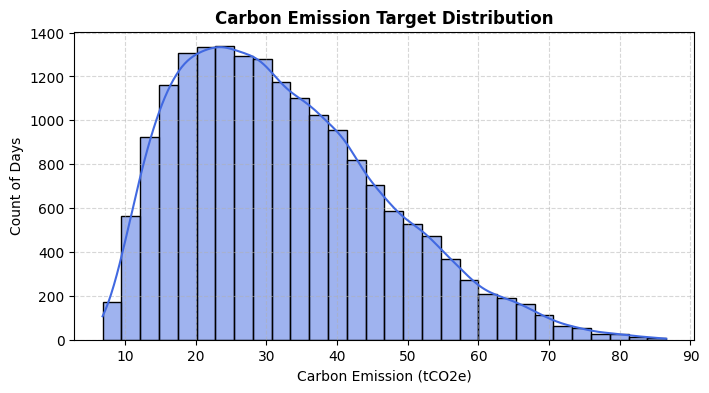

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Carbon_Emission_tCO2e_TARGET"], bins=30, kde=True, color="royalblue")
plt.title("Carbon Emission Target Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Carbon Emission (tCO2e)")
plt.ylabel("Count of Days")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Step 2.2: Plot a Boxplot of the Target to Check for Outliers

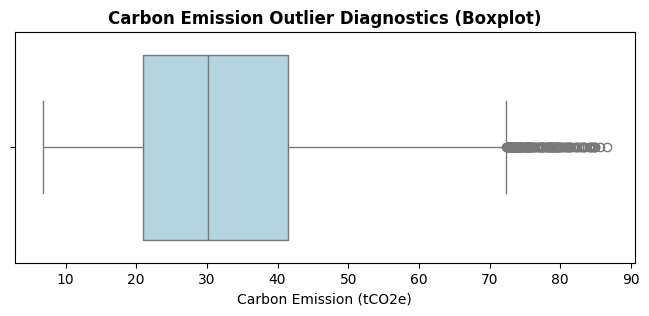

In [14]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Carbon_Emission_tCO2e_TARGET"], color="lightblue")
plt.title("Carbon Emission Outlier Diagnostics (Boxplot)", fontsize=12, fontweight='bold')
plt.xlabel("Carbon Emission (tCO2e)")
plt.show()

### Step 2.3: Compare Carbon Emissions Across Industry Sectors

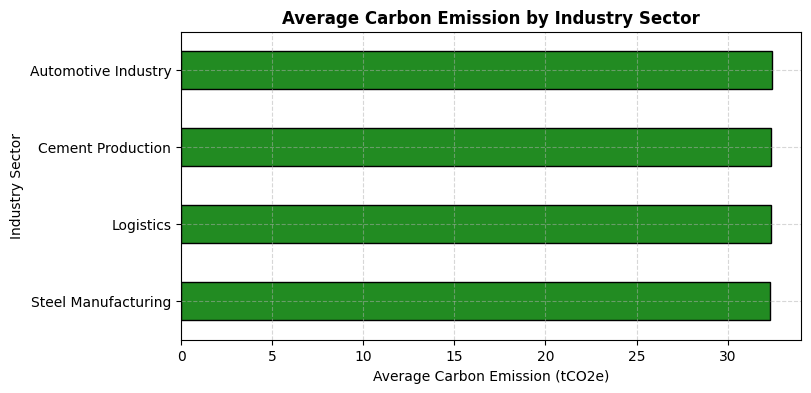

In [15]:
industry_avg = df.groupby("Industry_Sectors")["Carbon_Emission_tCO2e_TARGET"].mean().sort_values()

plt.figure(figsize=(8, 4))
industry_avg.plot(kind="barh", color="forestgreen", edgecolor="black")
plt.title("Average Carbon Emission by Industry Sector", fontsize=12, fontweight='bold')
plt.xlabel("Average Carbon Emission (tCO2e)")
plt.ylabel("Industry Sector")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Step 2.4: Plot the Correlation Heatmap

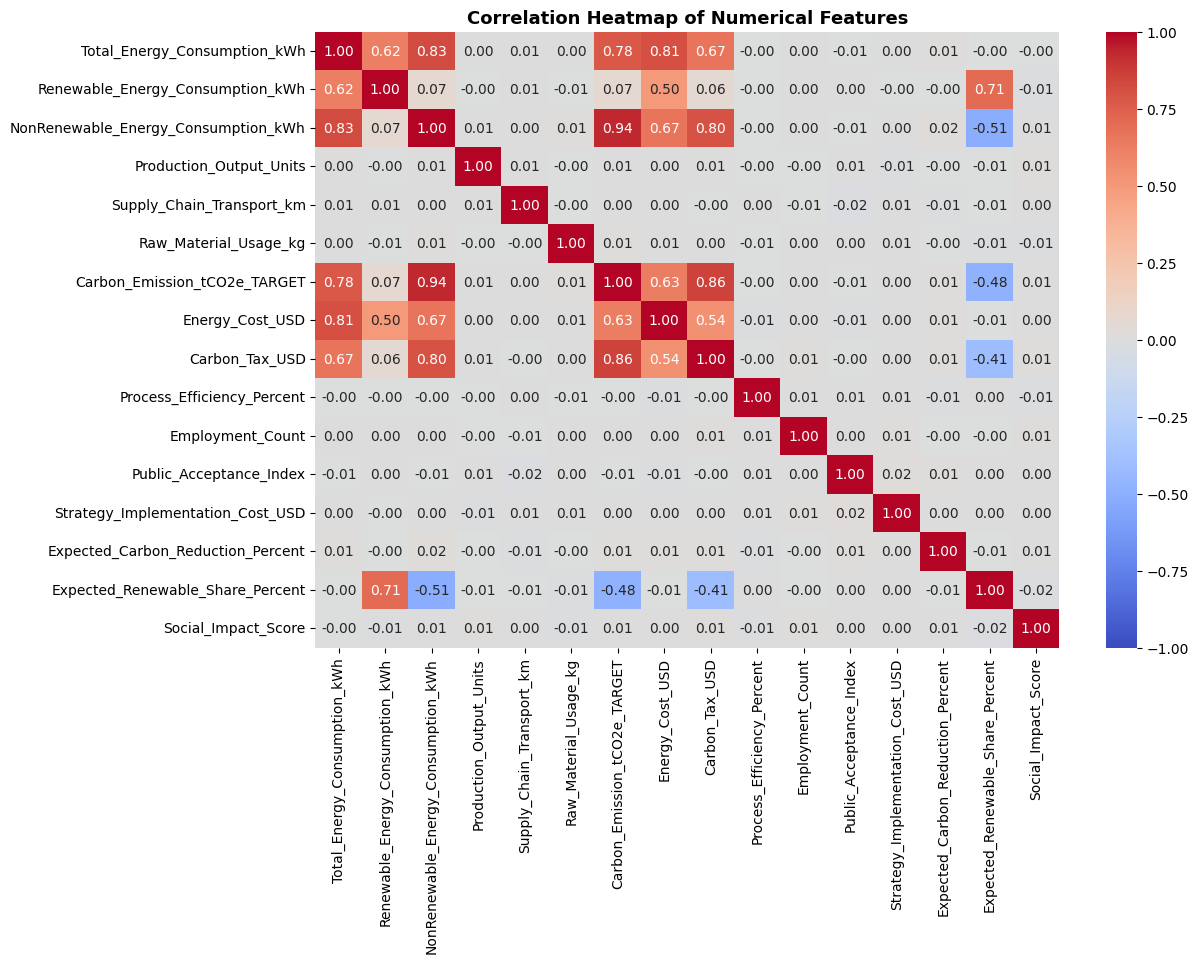

In [16]:
numeric_columns = df.select_dtypes(include=[np.number])
corr_matrix = numeric_columns.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features", fontsize=13, fontweight='bold')
plt.show()

### Step 2.5: Check Top Features Most Correlated with Carbon Emission

In [17]:
corr_with_target = corr_matrix["Carbon_Emission_tCO2e_TARGET"].sort_values(ascending=False)
print(corr_with_target)

Carbon_Emission_tCO2e_TARGET           1.000000
NonRenewable_Energy_Consumption_kWh    0.937198
Carbon_Tax_USD                         0.855654
Total_Energy_Consumption_kWh           0.777758
Energy_Cost_USD                        0.626154
Renewable_Energy_Consumption_kWh       0.070036
Expected_Carbon_Reduction_Percent      0.010295
Raw_Material_Usage_kg                  0.009820
Social_Impact_Score                    0.007216
Production_Output_Units                0.006059
Employment_Count                       0.004777
Supply_Chain_Transport_km              0.004581
Strategy_Implementation_Cost_USD       0.001160
Process_Efficiency_Percent            -0.003971
Public_Acceptance_Index               -0.005967
Expected_Renewable_Share_Percent      -0.476811
Name: Carbon_Emission_tCO2e_TARGET, dtype: float64


### Step 2.6: Count Supply Chain Transportation Modes

Supply_Chain_Transport_Mode
Ship     4581
Air      4567
Truck    4559
Rail     4543
Name: count, dtype: int64


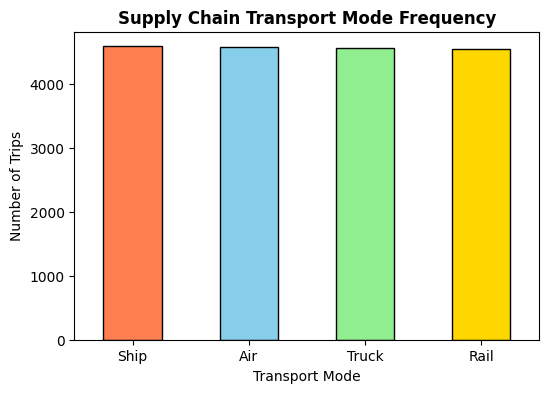

In [18]:
transport_counts = df["Supply_Chain_Transport_Mode"].value_counts()
print(transport_counts)

plt.figure(figsize=(6, 4))
transport_counts.plot(kind="bar", color=["coral", "skyblue", "lightgreen", "gold"], edgecolor="black")
plt.title("Supply Chain Transport Mode Frequency", fontsize=12, fontweight='bold')
plt.xlabel("Transport Mode")
plt.ylabel("Number of Trips")
plt.xticks(rotation=0)
plt.show()

### Step 2.7: Compare Renewable vs. Non-Renewable Energy Share

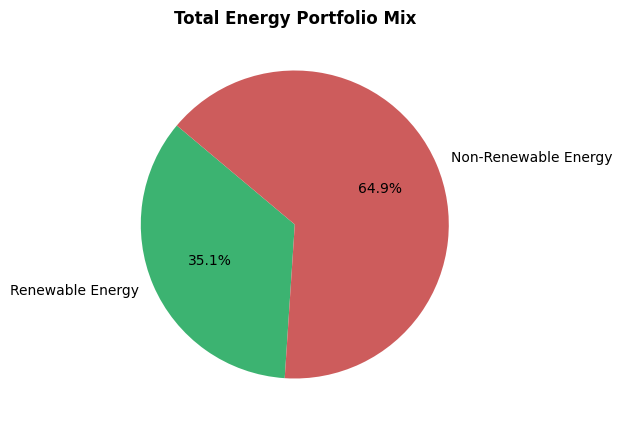

In [19]:
total_renewable = df["Renewable_Energy_Consumption_kWh"].sum()
total_non_renewable = df["NonRenewable_Energy_Consumption_kWh"].sum()

plt.figure(figsize=(5, 5))
plt.pie(
    [total_renewable, total_non_renewable],
    labels=["Renewable Energy", "Non-Renewable Energy"],
    autopct="%1.1f%%",
    colors=["mediumseagreen", "indianred"],
    startangle=140
)
plt.title("Total Energy Portfolio Mix", fontsize=12, fontweight='bold')
plt.show()


---
## Section 3: Data Preprocessing

### Step 3.1: Convert Date Strings to Standard Datetime

In [20]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date column successfully converted to datetime!")
print("Date range:", df["Date"].min(), "to", df["Date"].max())


Date column successfully converted to datetime!
Date range: 2024-01-01 00:00:00 to 2024-12-30 00:00:00


### Step 3.2: Sort the Data Chronologically per Company

In [21]:
df = df.sort_values(by=["Company_ID", "Date"]).reset_index(drop=True)

df[["Company_ID", "Date", "Total_Energy_Consumption_kWh", "Carbon_Emission_tCO2e_TARGET"]].head()


,Company_ID,Date,Total_Energy_Consumption_kWh,Carbon_Emission_tCO2e_TARGET
0,C001,2024-01-01,53751.61,12.5560
1,C001,2024-01-02,170872.89,35.3949
2,C001,2024-01-03,142777.96,30.4517
3,C001,2024-01-04,152532.15,49.5550
4,C001,2024-01-05,81647.43,16.8968


### Step 3.3: Define the Target Column Name

In [22]:
target = "Carbon_Emission_tCO2e_TARGET"
print("Target column:", target)


Target column: Carbon_Emission_tCO2e_TARGET


### Step 3.4: Define the 15 Operational Input Features

In [23]:
features = [
    "Total_Energy_Consumption_kWh",
    "Renewable_Energy_Consumption_kWh",
    "NonRenewable_Energy_Consumption_kWh",
    "Production_Output_Units",
    "Supply_Chain_Transport_km",
    "Raw_Material_Usage_kg",
    "Energy_Cost_USD",
    "Carbon_Tax_USD",
    "Process_Efficiency_Percent",
    "Employment_Count",
    "Public_Acceptance_Index",
    "Strategy_Implementation_Cost_USD",
    "Expected_Carbon_Reduction_Percent",
    "Expected_Renewable_Share_Percent",
    "Social_Impact_Score"
]

print(f"Total features selected: {len(features)}")
for i, col in enumerate(features, 1):
    print(f"{i:2d}. {col}")


Total features selected: 15
 1. Total_Energy_Consumption_kWh
 2. Renewable_Energy_Consumption_kWh
 3. NonRenewable_Energy_Consumption_kWh
 4. Production_Output_Units
 5. Supply_Chain_Transport_km
 6. Raw_Material_Usage_kg
 7. Energy_Cost_USD
 8. Carbon_Tax_USD
 9. Process_Efficiency_Percent
10. Employment_Count
11. Public_Acceptance_Index
12. Strategy_Implementation_Cost_USD
13. Expected_Carbon_Reduction_Percent
14. Expected_Renewable_Share_Percent
15. Social_Impact_Score


---
## Section 4: Feature Engineering

### Step 4.1: Understand the 60-Day Sliding Lookback Window

In [24]:
SEQUENCE_LENGTH = 60
print(f"Lookback window set to {SEQUENCE_LENGTH} days.")


Lookback window set to 60 days.


### Step 4.2: Define the `build_sequences()` Function

In [25]:
def build_sequences(data, feature_cols, target_col, seq_len=60):
    """Creates 3D sequences (Samples, 60 timesteps, 15 features) per company."""
    X_list = []
    y_list = []
    company_list = []
    
    for company_id in data["Company_ID"].unique():
        company_df = data[data["Company_ID"] == company_id].sort_values("Date")
        
        feature_values = company_df[feature_cols].values
        target_values = company_df[target_col].values
        
        for i in range(seq_len - 1, len(company_df)):
            # 60 days of features from (i - 59) up to day i inclusive
            X_list.append(feature_values[i - seq_len + 1 : i + 1])
            # Day i's carbon emission
            y_list.append([target_values[i]])
            company_list.append(company_id)
            
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32), np.array(company_list)

print("build_sequences function defined successfully!")


build_sequences function defined successfully!


### Step 4.3: Generate the Sequence Arrays

In [26]:
X, y, company_tags = build_sequences(df, features, target, seq_len=SEQUENCE_LENGTH)

print("X shape (Samples, Timesteps, Features):", X.shape)
print("y shape (Samples, Output)             :", y.shape)
print("Total number of sequences created     :", len(X))


X shape (Samples, Timesteps, Features): (15300, 60, 15)
y shape (Samples, Output)             : (15300, 1)
Total number of sequences created     : 15300


### Step 4.4: Split Data into 80% Training and 20% Testing

In [27]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw, comp_train, comp_test = train_test_split(
    X, y, company_tags, test_size=0.20, random_state=42, shuffle=True
)

print("Training sequences count:", len(X_train_raw))
print("Testing sequences count :", len(X_test_raw))


Training sequences count: 12240
Testing sequences count : 3060


### Step 4.5: Initialize Min-Max Scalers

In [28]:
feature_scaler = MinMaxScaler(feature_range=(0, 1))

target_scaler = MinMaxScaler(feature_range=(0, 1))

print("Scalers initialized successfully!")


Scalers initialized successfully!


### Step 4.6: Fit Scalers Strictly on the Training Data

In [29]:
n_train = X_train_raw.shape[0]
n_test = X_test_raw.shape[0]
timesteps = X_train_raw.shape[1]
n_feats = X_train_raw.shape[2]

feature_scaler.fit(X_train_raw.reshape(-1, n_feats))

target_scaler.fit(y_train_raw)

print("Scalers fitted strictly on training data!")
print(f"Target minimum in training: {target_scaler.data_min_[0]:.2f} tCO2e")
print(f"Target maximum in training: {target_scaler.data_max_[0]:.2f} tCO2e")


Scalers fitted strictly on training data!
Target minimum in training: 6.90 tCO2e
Target maximum in training: 86.57 tCO2e


### Step 4.7: Transform Both Training and Testing Sets

In [30]:
X_train = feature_scaler.transform(X_train_raw.reshape(-1, n_feats)).reshape(n_train, timesteps, n_feats)
X_test = feature_scaler.transform(X_test_raw.reshape(-1, n_feats)).reshape(n_test, timesteps, n_feats)

y_train = target_scaler.transform(y_train_raw)
y_test = target_scaler.transform(y_test_raw)

print("Data transformation complete!")
print("X_train scaled range:", X_train.min(), "to", X_train.max())
print("y_train scaled range:", y_train.min(), "to", y_train.max())


Data transformation complete!
X_train scaled range: 0.0 to 1.0
y_train scaled range: 0.0 to 1.0


---
## Section 5: Model Architecture & Training

### Step 5.1: Build the Stacked LSTM Architecture

In [31]:
model = Sequential([
    Input(shape=(SEQUENCE_LENGTH, len(features))),
    LSTM(128, return_sequences=True),
    Dropout(0.20),
    LSTM(64, return_sequences=False),
    Dropout(0.20),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

print("Model architecture built successfully!")


Model architecture built successfully!


### Step 5.2: Compile the Model

In [32]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mae"]
)

print("Model compiled successfully!")


Model compiled successfully!


### Step 5.3: View the Model Summary (`model.summary()`)

In [33]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 128)        │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 125,249 (489.25 KB)

 Trainable params: 125,249 (489.25 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5.4: Set Up Smart Training Callbacks (EarlyStopping & ReduceLROnPlateau)

In [34]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

callbacks_list = [early_stop, reduce_lr]
print("Callbacks configured successfully!")


Callbacks configured successfully!


### Step 5.5: Train the Model (`model.fit`)

In [50]:
EPOCHS = 30
BATCH_SIZE = 32

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,  # Uses 20% of X_train for validation
    callbacks=callbacks_list,
    verbose=1
)
model.evaluate(X_test, y_test)

print("Training finished successfully!")


Epoch 1/50
306/306 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - loss: 0.0033 - mae: 0.0439 - val_loss: 0.0031 - val_mae: 0.0428 - learning_rate: 3.1250e-05
Epoch 2/50
306/306 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - loss: 0.0033 - mae: 0.0441 - val_loss: 0.0031 - val_mae: 0.0427 - learning_rate: 3.1250e-05
Epoch 3/50
306/306 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - loss: 0.0033 - mae: 0.0437 - val_loss: 0.0031 - val_mae: 0.0428 - learning_rate: 3.1250e-05
Epoch 4/50
306/306 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - loss: 0.0032 - mae: 0.0438 - val_loss: 0.0031 - val_mae: 0.0428 - learning_rate: 3.1250e-05
Epoch 5/50
306/306 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - loss: 0.0032 - mae: 0.0438 - val_loss: 0.0031 - val_mae: 0.0428 - learning_rate: 3.1250e-05
Epoch 6/50
305/306 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0033 - mae: 0.0441 
Epoch 6: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
306/306 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - loss: 0.0033 - mae: 0.0441 - val_loss: 0.0031 - val_mae

96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step


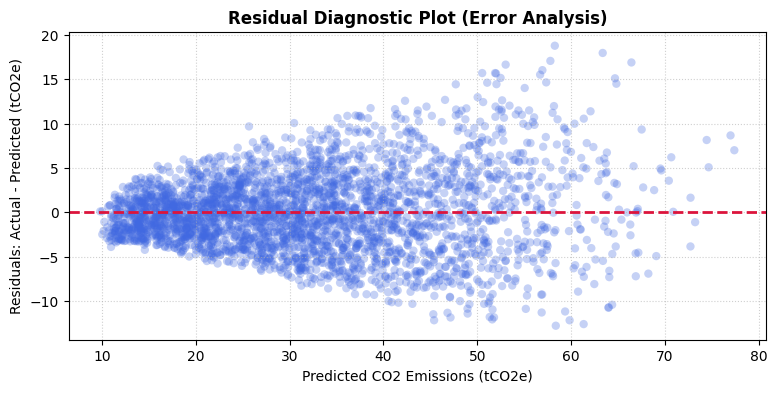

In [52]:
y_pred_scaled = model.predict(X_test)

y_pred = target_scaler.inverse_transform(y_pred_scaled)
y_actual = target_scaler.inverse_transform(y_test)

residuals = y_actual - y_pred

plt.figure(figsize=(9, 4))
plt.scatter(y_pred, residuals, alpha=0.3, color="royalblue", edgecolor="none")
plt.axhline(0, color="crimson", linestyle="--", linewidth=2)
plt.title("Residual Diagnostic Plot (Error Analysis)", fontsize=12, fontweight="bold")
plt.xlabel("Predicted CO2 Emissions (tCO2e)")
plt.ylabel("Residuals: Actual - Predicted (tCO2e)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

---
## Section 6: Model Evaluation & Diagnostics

### Step 6.1: Predict on the Test Set (`model.predict`)

In [36]:
y_pred_scaled = model.predict(X_test)

print("Predictions generated!")
print("Predicted array shape:", y_pred_scaled.shape)


96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step  
Predictions generated!
Predicted array shape: (3060, 1)


### Step 6.2: Invert Predictions Back to Real Units ($tCO_2e$)

In [37]:
y_pred = target_scaler.inverse_transform(y_pred_scaled)
y_actual = target_scaler.inverse_transform(y_test)

print("Inversion complete!")
print("Sample actual value   :", y_actual[0][0], "tCO2e")
print("Sample predicted value:", y_pred[0][0], "tCO2e")


Inversion complete!
Sample actual value   : 23.4011 tCO2e
Sample predicted value: 20.635515 tCO2e


### Step 6.3: Calculate Evaluation Metrics (MAE, RMSE, R² Score)

In [38]:
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print("=== MODEL PERFORMANCE BENCHMARKS ===")
print(f"Mean Absolute Error (MAE) : {mae:.2f} tCO2e")
print(f"Root Mean Squared Error   : {rmse:.2f} tCO2e")
print(f"R² Score (Goodness of Fit): {r2:.4f} ({r2*100:.2f}%)")


=== MODEL PERFORMANCE BENCHMARKS ===
Mean Absolute Error (MAE) : 3.40 tCO2e
Root Mean Squared Error   : 4.38 tCO2e
R² Score (Goodness of Fit): 0.9073 (90.73%)


### Step 6.4: Plot Training vs. Validation Loss Curves

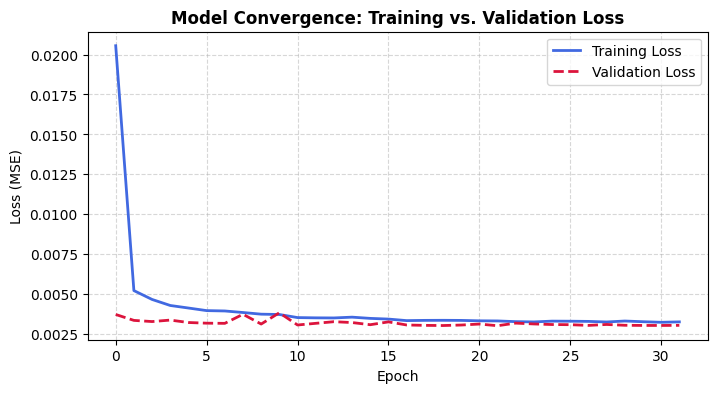

In [39]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss", color="royalblue", lw=2)
plt.plot(history.history["val_loss"], label="Validation Loss", color="crimson", lw=2, linestyle="--")
plt.title("Model Convergence: Training vs. Validation Loss", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Step 6.5: Plot Actual vs. Predicted Emissions (First 100 Test Samples)

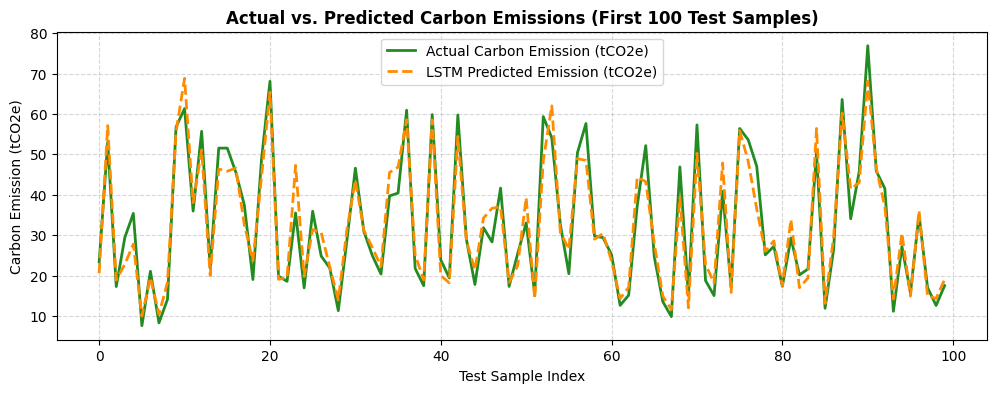

In [40]:
plt.figure(figsize=(12, 4))
plt.plot(y_actual[:100], label="Actual Carbon Emission (tCO2e)", color="forestgreen", lw=2)
plt.plot(y_pred[:100], label="LSTM Predicted Emission (tCO2e)", color="darkorange", lw=2, linestyle="--")
plt.title("Actual vs. Predicted Carbon Emissions (First 100 Test Samples)", fontsize=12, fontweight='bold')
plt.xlabel("Test Sample Index")
plt.ylabel("Carbon Emission (tCO2e)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Step 6.6: Create a `models/` Directory for Saving Artifacts

In [41]:
os.makedirs("models", exist_ok=True)
print("Folder 'models/' is ready!")


Folder 'models/' is ready!


### Step 6.7: Save the Trained Neural Network (`.keras`)

In [42]:
model.save("models/lstm_model.keras")
print("Trained model saved to: models/lstm_model.keras")


Trained model saved to: models/lstm_model.keras


### Step 6.8: Save the Fitted Scalers (`.joblib`)

In [43]:
joblib.dump(feature_scaler, "models/feature_scaler.joblib")
joblib.dump(target_scaler, "models/target_scaler.joblib")

print("Scalers saved to: models/feature_scaler.joblib and models/target_scaler.joblib")


Scalers saved to: models/feature_scaler.joblib and models/target_scaler.joblib


### Step 6.9: Save Evaluation Metrics to JSON (`metrics.json`)

In [44]:
metrics_data = {
    "mae": float(mae),
    "rmse": float(rmse),
    "r2_score": float(r2),
    "total_test_samples": int(len(X_test)),
    "sequence_length_days": int(SEQUENCE_LENGTH)
}

with open("models/metrics.json", "w") as f:
    json.dump(metrics_data, f, indent=4)

print("Metrics saved to: models/metrics.json")


Metrics saved to: models/metrics.json


### Step 6.10: Save Test Data Arrays to `.npz`

In [45]:
np.savez_compressed(
    "models/test_data.npz",
    X_test=X_test,
    actual=y_actual,
    predicted=y_pred,
    companies=comp_test
)

print("Test arrays saved to: models/test_data.npz")


Test arrays saved to: models/test_data.npz


---
## Section 7: Decarbonization Policy & What-If Simulation

*"What happens to daily carbon emissions if facilities reduce non-renewable fossil energy consumption by 10%, 20%, or 30%?"*


### Step 7.1: Define the `simulate_reduction()` Function

In [46]:
def simulate_reduction(reduction_pct, X_test_base, feature_names, trained_model, f_scaler, t_scaler):
    """Simulates what happens when non-renewable energy is cut by reduction_pct%."""
    col_idx = feature_names.index("NonRenewable_Energy_Consumption_kWh")
    
    f_min = f_scaler.data_min_[col_idx]
    f_max = f_scaler.data_max_[col_idx]
    
    X_sim = X_test_base.copy()
    
    real_kwh = X_sim[:, :, col_idx] * (f_max - f_min) + f_min
    
    reduced_kwh = real_kwh * (1.0 - reduction_pct / 100.0)
    
    X_sim[:, :, col_idx] = (reduced_kwh - f_min) / (f_max - f_min)
    
    pred_scaled = trained_model.predict(X_sim, verbose=0)
    
    return t_scaler.inverse_transform(pred_scaled)

print("Simulation function defined successfully!")


Simulation function defined successfully!


### Step 7.2: Run What-If Scenarios (Current, 10% Cut, 20% Cut, 30% Cut)

In [47]:
scenarios = [0, 10, 20, 30]
scenario_results = {}

for pct in scenarios:
    label = f"{pct}% Reduction" if pct > 0 else "Current (Baseline)"
    predicted_emissions = simulate_reduction(pct, X_test, features, model, feature_scaler, target_scaler)
    scenario_results[label] = float(np.mean(predicted_emissions))

print("=== DECARBONIZATION WHAT-IF SCENARIOS ===")
for label, avg_emission in scenario_results.items():
    print(f"{label:20s}: {avg_emission:.2f} tCO2e (Average per facility)")


=== DECARBONIZATION WHAT-IF SCENARIOS ===
Current (Baseline)  : 32.35 tCO2e (Average per facility)
10% Reduction       : 31.18 tCO2e (Average per facility)
20% Reduction       : 30.00 tCO2e (Average per facility)
30% Reduction       : 28.82 tCO2e (Average per facility)


### Step 7.3: Plot the Decarbonization Scenario Comparison Bar Chart

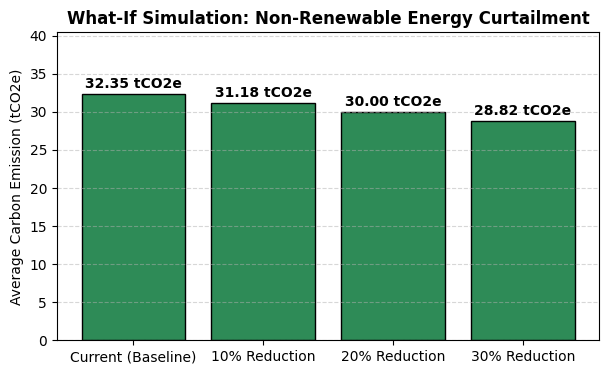

In [48]:
plt.figure(figsize=(7, 4))
bars = plt.bar(scenario_results.keys(), scenario_results.values(), color="seagreen", edgecolor="black")
plt.title("What-If Simulation: Non-Renewable Energy Curtailment", fontsize=12, fontweight='bold')
plt.ylabel("Average Carbon Emission (tCO2e)")
plt.ylim(0, max(scenario_results.values()) * 1.25)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.8, f"{height:.2f} tCO2e", ha="center", fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()
